In [1]:
# IntelliMaintain-AI
# Step 1: Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

print("IntelliMaintain-AI")
print("Libraries imported successfully!")

IntelliMaintain-AI
Libraries imported successfully!


In [2]:
# Step 2: Load the industrial dataset

import pandas as pd
from pathlib import Path

# Locate the dataset
candidates = [
    Path.cwd() / "data" / "raw" / "ai4i2020.csv",
    Path.cwd().parent / "data" / "raw" / "ai4i2020.csv"
]

DATA_PATH = next(
    (path for path in candidates if path.exists()),
    None
)

if DATA_PATH is None:
    raise FileNotFoundError("Dataset not found!")

# Load CSV
df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully!")
print("Dataset location:", DATA_PATH)

Dataset loaded successfully!
Dataset location: c:\Users\Anushriya R\OneDrive\Desktop\intellimaintain-ai\data\raw\ai4i2020.csv


In [3]:
# Step 3: Understand our dataset

print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nFirst 5 Records:")
display(df.head())

Dataset Shape: (10000, 14)

Column Names:
['UDI', 'Product ID', 'Type', 'Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]', 'Machine failure', 'TWF', 'HDF', 'PWF', 'OSF', 'RNF']

First 5 Records:


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [4]:
# Step 4: Dataset information

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  str    
 2   Type                     10000 non-null  str    
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Machine failure          10000 non-null  int64  
 9   TWF                      10000 non-null  int64  
 10  HDF                      10000 non-null  int64  
 11  PWF                      10000 non-null  int64  
 12  OSF                      10000 non-null  int64  
 13  RNF                      10000 non-null  int64  
dtypes: float64(3), int64(9), str(2)
me

In [5]:
# Step 5: Data Quality Analysis

# Check missing values
print("Missing Values:")
print(df.isnull().sum())

# Check duplicate records
print("\nDuplicate Rows:")
print(df.duplicated().sum())

# Check statistical summary
print("\nStatistical Summary:")
display(df.describe())

Missing Values:
UDI                        0
Product ID                 0
Type                       0
Air temperature [K]        0
Process temperature [K]    0
Rotational speed [rpm]     0
Torque [Nm]                0
Tool wear [min]            0
Machine failure            0
TWF                        0
HDF                        0
PWF                        0
OSF                        0
RNF                        0
dtype: int64

Duplicate Rows:
0

Statistical Summary:


,UDI,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
count,10000.00000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000
mean,5000.50000,300.004930,310.005560,1538.776100,39.986910,107.951000,0.033900,0.004600,0.011500,0.009500,0.009800,0.00190
std,2886.89568,2.000259,1.483734,179.284096,9.968934,63.654147,0.180981,0.067671,0.106625,0.097009,0.098514,0.04355
min,1.00000,295.300000,305.700000,1168.000000,3.800000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
25%,2500.75000,298.300000,308.800000,1423.000000,33.200000,53.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
50%,5000.50000,300.100000,310.100000,1503.000000,40.100000,108.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
75%,7500.25000,301.500000,311.100000,1612.000000,46.800000,162.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
max,10000.00000,304.500000,313.800000,2886.000000,76.600000,253.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.00000


In [8]:
# Step 6: Machine Failure Distribution

print("Machine Failure Counts:")
print(df["Machine failure"].value_counts())

print("\nFailure Percentages:")
print(
    df["Machine failure"]
    .value_counts(normalize=True) * 100
)

Machine Failure Counts:
Machine failure
0    9661
1     339
Name: count, dtype: int64

Failure Percentages:
Machine failure
0    96.61
1     3.39
Name: proportion, dtype: float64


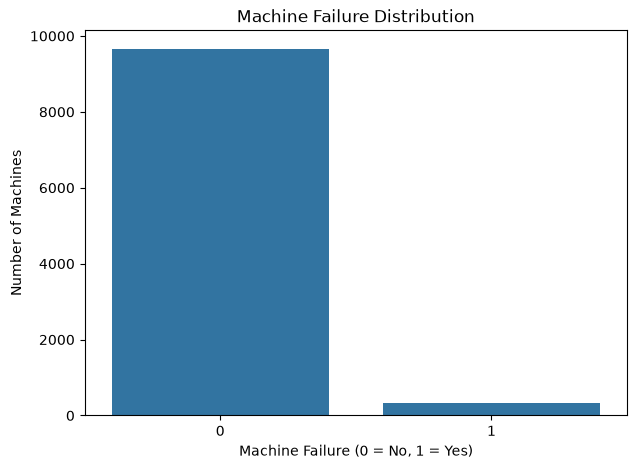

In [9]:
# Step 7: Failure Visualization

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="Machine failure"
)

plt.title("Machine Failure Distribution")
plt.xlabel("Machine Failure (0 = No, 1 = Yes)")
plt.ylabel("Number of Machines")

plt.show()

In [10]:
# Step 8: Failure Type Analysis

failure_columns = ["TWF", "HDF", "PWF", "OSF", "RNF"]

failure_counts = df[failure_columns].sum().sort_values(
    ascending=False
)

print("Failure Type Counts:")
print(failure_counts)

Failure Type Counts:
HDF    115
OSF     98
PWF     95
TWF     46
RNF     19
dtype: int64


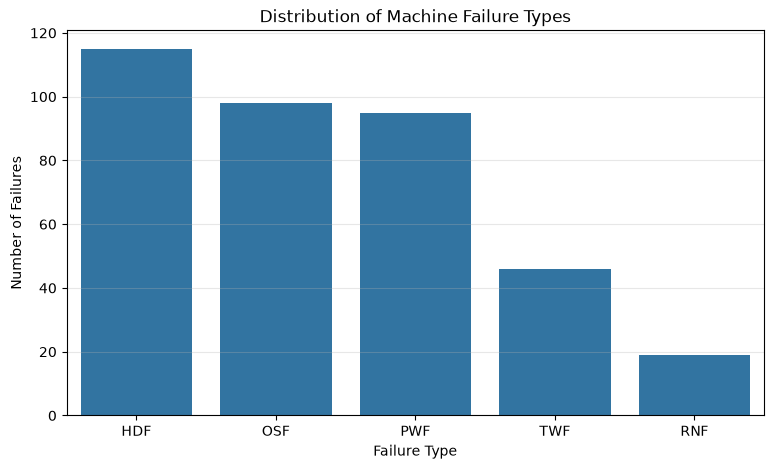

In [11]:
# Step 9: Visualize Failure Types

plt.figure(figsize=(9, 5))

sns.barplot(
    x=failure_counts.index,
    y=failure_counts.values
)

plt.title("Distribution of Machine Failure Types")
plt.xlabel("Failure Type")
plt.ylabel("Number of Failures")

plt.grid(axis="y", alpha=0.3)
plt.show()

In [12]:
# Step 10: Sensor Analysis

sensor_columns = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

display(
    df.groupby("Machine failure")[sensor_columns].mean()
)

,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min]
Machine failure,,,,,
0,299.973999,309.995570,1540.260014,39.629655,106.693717
1,300.886431,310.290265,1496.486726,50.168142,143.781711


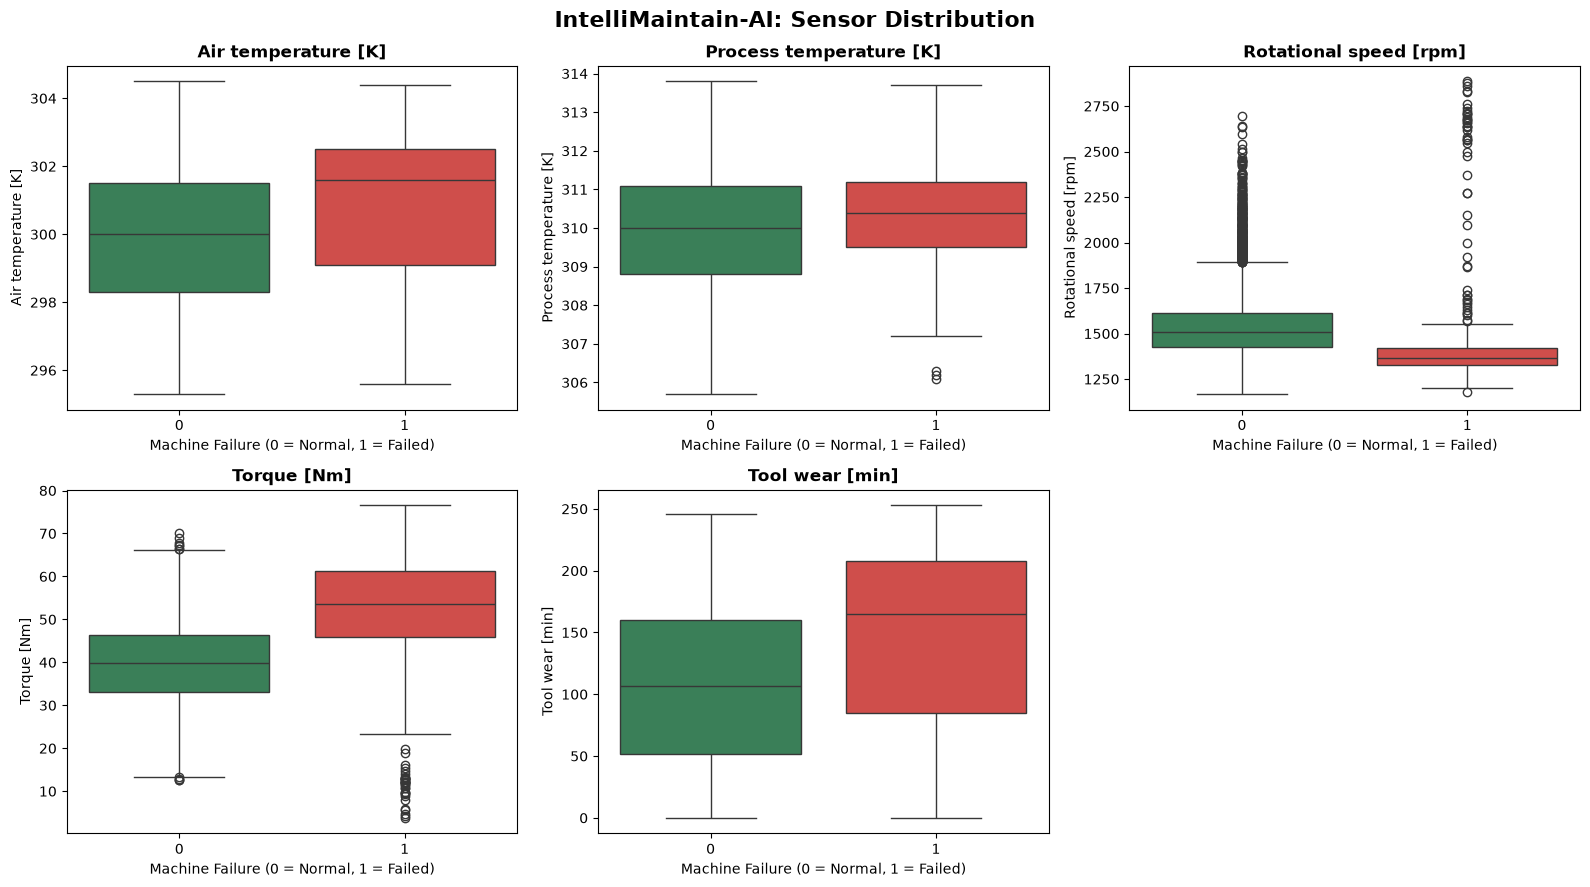

In [20]:
# Step 11: Sensor Distribution Boxplots
# Green = Normal | Red = Failed

import matplotlib.pyplot as plt
import seaborn as sns

sensor_columns = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

custom_palette = {
    0: "#2E8B57",  # Green
    1: "#E53935"   # Red
}

fig, axes = plt.subplots(2, 3, figsize=(16, 9))

for ax, column in zip(axes.flat, sensor_columns):
    sns.boxplot(
        data=df,
        x="Machine failure",
        y=column,
        hue="Machine failure",
        palette=custom_palette,
        legend=False,
        ax=ax
    )

    ax.set_title(column, fontsize=12, fontweight="bold")
    ax.set_xlabel("Machine Failure (0 = Normal, 1 = Failed)")
    ax.set_ylabel(column)

axes.flat[-1].set_visible(False)

plt.suptitle(
    "IntelliMaintain-AI: Sensor Distribution",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

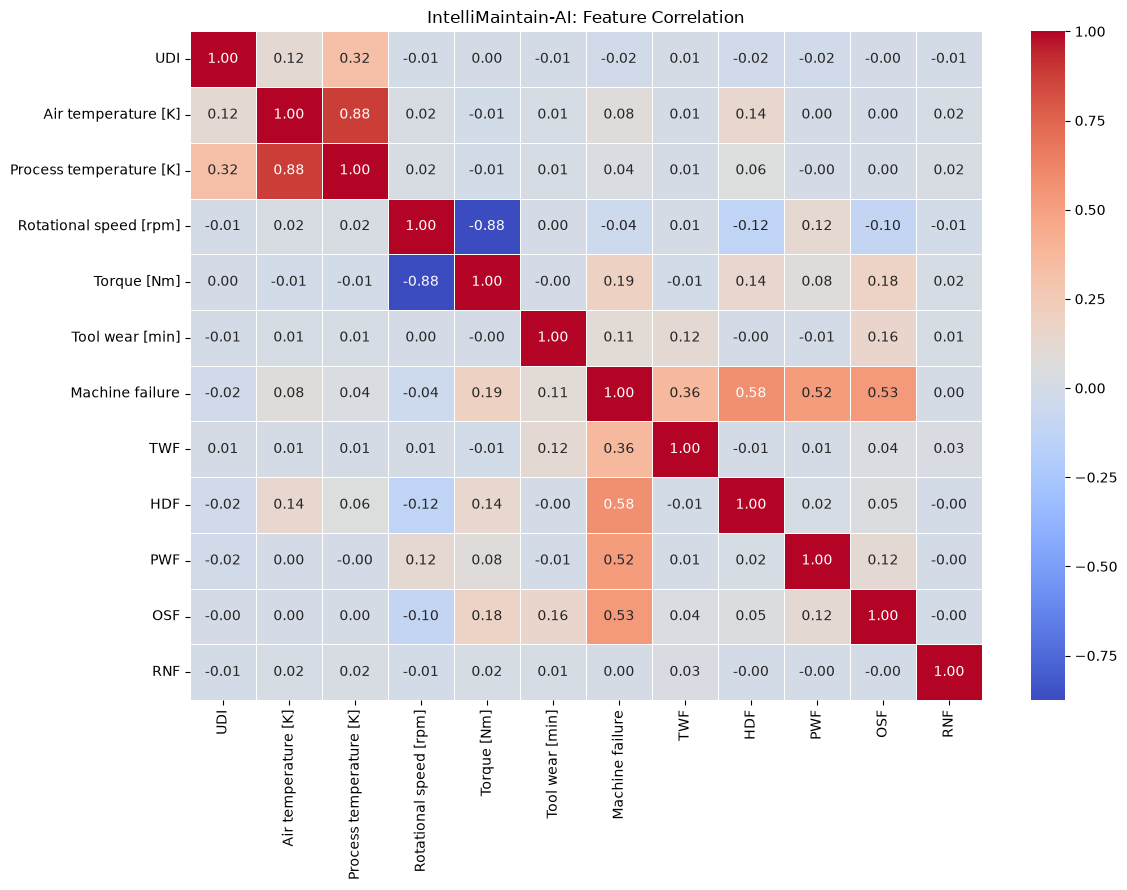

In [15]:
# Step 12: Correlation Heatmap

numeric_df = df.select_dtypes(include="number")

correlation = numeric_df.corr()

plt.figure(figsize=(12, 9))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("IntelliMaintain-AI: Feature Correlation")
plt.tight_layout()
plt.show()

In [16]:
# Step 13: Correlation with Machine Failure

failure_correlation = (
    correlation["Machine failure"]
    .drop("Machine failure")
    .sort_values(ascending=False)
)

display(failure_correlation)

HDF                        0.575800
OSF                        0.531083
PWF                        0.522812
TWF                        0.362904
Torque [Nm]                0.191321
Tool wear [min]            0.105448
Air temperature [K]        0.082556
Process temperature [K]    0.035946
RNF                        0.004516
UDI                       -0.022892
Rotational speed [rpm]    -0.044188
Name: Machine failure, dtype: float64

In [21]:
# Step 14: Feature Selection

# Input features
features = [
    "Type",
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

# Target variable
target = "Machine failure"

X = df[features].copy()
y = df[target].copy()

print("Feature Selection Completed!")

print("\nInput Features:")
print(X.columns.tolist())

print("\nTarget Variable:")
print(target)

print("\nFeature Dataset Shape:", X.shape)
print("Target Dataset Shape:", y.shape)

Feature Selection Completed!

Input Features:
['Type', 'Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]']

Target Variable:
Machine failure

Feature Dataset Shape: (10000, 6)
Target Dataset Shape: (10000,)


In [22]:
# Check class distribution

print("Normal Machines:", (y == 0).sum())
print("Failed Machines:", (y == 1).sum())

print("\nClass Distribution:")
print(y.value_counts(normalize=True) * 100)

Normal Machines: 9661
Failed Machines: 339

Class Distribution:
Machine failure
0    96.61
1     3.39
Name: proportion, dtype: float64


In [23]:
# Step 15: Train-Test Split

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Data Shape:", X_train.shape)
print("Testing Data Shape:", X_test.shape)

print("\nTraining Target Distribution:")
print(y_train.value_counts())

print("\nTesting Target Distribution:")
print(y_test.value_counts())

Training Data Shape: (8000, 6)
Testing Data Shape: (2000, 6)

Training Target Distribution:
Machine failure
0    7729
1     271
Name: count, dtype: int64

Testing Target Distribution:
Machine failure
0    1932
1      68
Name: count, dtype: int64


In [24]:
# Verify class proportions

print("Training Failure Percentage:")
print(round(y_train.mean() * 100, 2), "%")

print("\nTesting Failure Percentage:")
print(round(y_test.mean() * 100, 2), "%")

Training Failure Percentage:
3.39 %

Testing Failure Percentage:
3.4 %


In [25]:
# Save train and test datasets

from pathlib import Path

processed_dir = Path("data/processed")
processed_dir.mkdir(parents=True, exist_ok=True)

train_data = X_train.copy()
train_data["Machine failure"] = y_train

test_data = X_test.copy()
test_data["Machine failure"] = y_test

train_data.to_csv(
    processed_dir / "train.csv",
    index=False
)

test_data.to_csv(
    processed_dir / "test.csv",
    index=False
)

print("Training and testing datasets saved successfully!")

Training and testing datasets saved successfully!


In [26]:
# Step 16: Data Preprocessing

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline

categorical_features = ["Type"]

numerical_features = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

preprocessor = ColumnTransformer(
    transformers=[
        (
            "cat",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        ),
        (
            "num",
            "passthrough",
            numerical_features
        )
    ]
)

print("Preprocessor created successfully!")
print("Categorical features:", categorical_features)
print("Numerical features:", numerical_features)

Preprocessor created successfully!
Categorical features: ['Type']
Numerical features: ['Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]']


In [27]:
# Step 17: Random Forest Model

from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

rf_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", RandomForestClassifier(
            n_estimators=300,
            max_depth=12,
            min_samples_split=5,
            min_samples_leaf=2,
            class_weight="balanced",
            random_state=42,
            n_jobs=-1
        ))
    ]
)

print("Random Forest model created successfully!")

Random Forest model created successfully!


In [28]:
# Step 18: Train Random Forest

rf_model.fit(X_train, y_train)

print("Random Forest training completed!")

Random Forest training completed!


In [29]:
# Step 19: Predict machine failures

rf_predictions = rf_model.predict(X_test)

rf_probabilities = rf_model.predict_proba(X_test)[:, 1]

print("Predictions completed!")

print("\nFirst 20 predictions:")
print(rf_predictions[:20])

Predictions completed!

First 20 predictions:
[1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]


In [30]:
# Step 20: Random Forest Evaluation

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    classification_report,
    confusion_matrix
)

print("========== RANDOM FOREST RESULTS ==========")

print("Accuracy:",
      accuracy_score(y_test, rf_predictions))

print("Precision:",
      precision_score(y_test, rf_predictions, zero_division=0))

print("Recall:",
      recall_score(y_test, rf_predictions, zero_division=0))

print("F1 Score:",
      f1_score(y_test, rf_predictions, zero_division=0))

print("PR-AUC:",
      average_precision_score(y_test, rf_probabilities))

print("\nClassification Report:")
print(classification_report(
    y_test,
    rf_predictions,
    zero_division=0
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, rf_predictions))

========== RANDOM FOREST RESULTS ==========
Accuracy: 0.97
Precision: 0.5408163265306123
Recall: 0.7794117647058824
F1 Score: 0.6385542168674698
PR-AUC: 0.7348738043197702

Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.98      0.98      1932
           1       0.54      0.78      0.64        68

    accuracy                           0.97      2000
   macro avg       0.77      0.88      0.81      2000
weighted avg       0.98      0.97      0.97      2000


Confusion Matrix:
[[1887   45]
 [  15   53]]


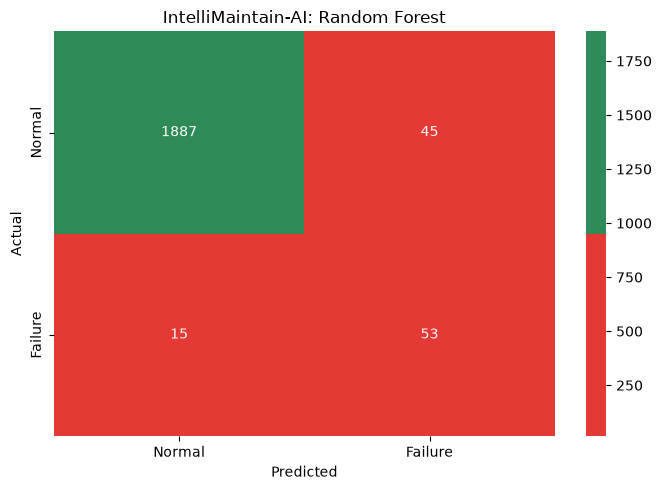

In [31]:
# Step 21: Confusion Matrix Visualization

import matplotlib.pyplot as plt
import seaborn as sns

cm = confusion_matrix(y_test, rf_predictions)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap=sns.color_palette(["#E53935", "#2E8B57"], as_cmap=True),
    xticklabels=["Normal", "Failure"],
    yticklabels=["Normal", "Failure"]
)

plt.title("IntelliMaintain-AI: Random Forest")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.tight_layout()
plt.show()

In [32]:
# Step 22: XGBoost Model

from xgboost import XGBClassifier
from sklearn.pipeline import Pipeline

# Handle class imbalance
scale_weight = (y_train == 0).sum() / (y_train == 1).sum()

xgb_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", XGBClassifier(
            n_estimators=400,
            max_depth=5,
            learning_rate=0.05,
            subsample=0.8,
            colsample_bytree=0.8,
            scale_pos_weight=scale_weight,
            eval_metric="logloss",
            random_state=42,
            n_jobs=-1
        ))
    ]
)

print("XGBoost model created successfully!")
print("Scale positive weight:", round(scale_weight, 2))

XGBoost model created successfully!
Scale positive weight: 28.52


In [33]:
# Step 23: Train XGBoost

xgb_model.fit(X_train, y_train)

print("XGBoost training completed!")

XGBoost training completed!


In [34]:
# Step 24: XGBoost Predictions

xgb_predictions = xgb_model.predict(X_test)

xgb_probabilities = xgb_model.predict_proba(X_test)[:, 1]

print("XGBoost predictions completed!")
print(xgb_predictions[:20])

XGBoost predictions completed!
[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]


In [35]:
# Step 25: XGBoost Evaluation

print("========== XGBOOST RESULTS ==========")

print("Accuracy:",
      accuracy_score(y_test, xgb_predictions))

print("Precision:",
      precision_score(y_test, xgb_predictions, zero_division=0))

print("Recall:",
      recall_score(y_test, xgb_predictions, zero_division=0))

print("F1 Score:",
      f1_score(y_test, xgb_predictions, zero_division=0))

print("PR-AUC:",
      average_precision_score(y_test, xgb_probabilities))

print("\nClassification Report:")
print(classification_report(
    y_test,
    xgb_predictions,
    zero_division=0
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, xgb_predictions))

========== XGBOOST RESULTS ==========
Accuracy: 0.979
Precision: 0.6547619047619048
Recall: 0.8088235294117647
F1 Score: 0.7236842105263158
PR-AUC: 0.8391232876676864

Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.98      0.99      1932
           1       0.65      0.81      0.72        68

    accuracy                           0.98      2000
   macro avg       0.82      0.90      0.86      2000
weighted avg       0.98      0.98      0.98      2000


Confusion Matrix:
[[1903   29]
 [  13   55]]


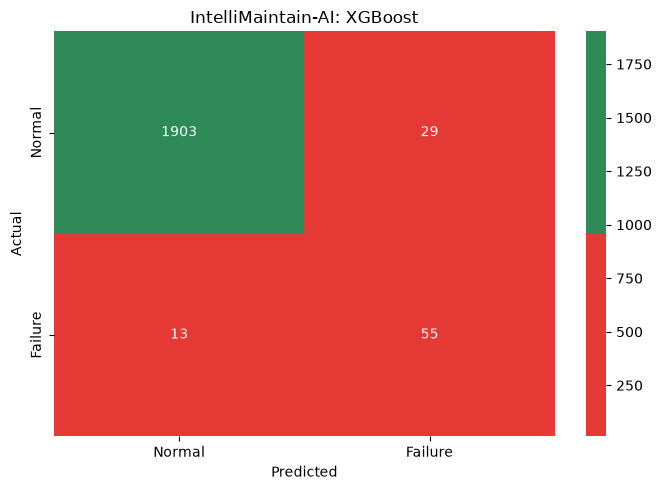

In [36]:
# Step 26: XGBoost Confusion Matrix

cm_xgb = confusion_matrix(y_test, xgb_predictions)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_xgb,
    annot=True,
    fmt="d",
    cmap=sns.color_palette(
        ["#E53935", "#2E8B57"],
        as_cmap=True
    ),
    xticklabels=["Normal", "Failure"],
    yticklabels=["Normal", "Failure"]
)

plt.title("IntelliMaintain-AI: XGBoost")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.tight_layout()
plt.show()

In [37]:
# Step 27: Model Comparison

import pandas as pd

results = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score",
        "PR-AUC"
    ],
    "Random Forest": [
        accuracy_score(y_test, rf_predictions),
        precision_score(y_test, rf_predictions),
        recall_score(y_test, rf_predictions),
        f1_score(y_test, rf_predictions),
        average_precision_score(y_test, rf_probabilities)
    ],
    "XGBoost": [
        accuracy_score(y_test, xgb_predictions),
        precision_score(y_test, xgb_predictions),
        recall_score(y_test, xgb_predictions),
        f1_score(y_test, xgb_predictions),
        average_precision_score(y_test, xgb_probabilities)
    ]
})

print(results.round(4))

results.to_csv(
    "data/processed/model_comparison.csv",
    index=False
)

print("\nModel comparison saved successfully!")

      Metric  Random Forest  XGBoost
0   Accuracy         0.9700   0.9790
1  Precision         0.5408   0.6548
2     Recall         0.7794   0.8088
3   F1 Score         0.6386   0.7237
4     PR-AUC         0.7349   0.8391

Model comparison saved successfully!


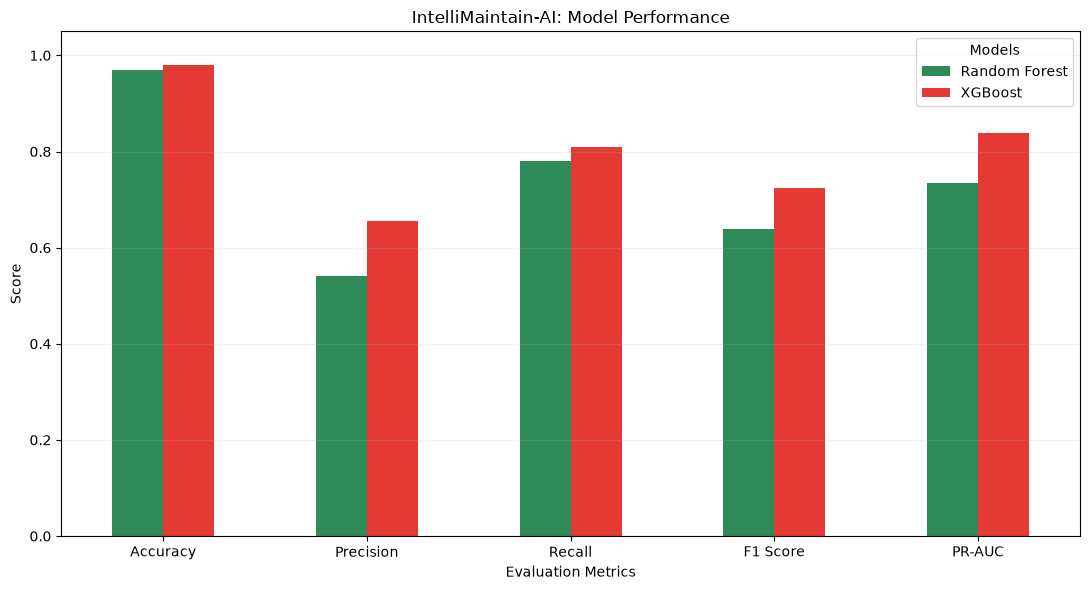

In [38]:
# Step 28: Model Comparison Visualization

comparison = results.set_index("Metric")

ax = comparison.plot(
    kind="bar",
    figsize=(11, 6),
    color=["#2E8B57", "#E53935"]
)

plt.title("IntelliMaintain-AI: Model Performance")
plt.ylabel("Score")
plt.xlabel("Evaluation Metrics")
plt.ylim(0, 1.05)
plt.xticks(rotation=0)
plt.legend(title="Models")
plt.grid(axis="y", alpha=0.2)

plt.tight_layout()
plt.show()

In [39]:
# Step 29: SHAP Explainability

import shap
import numpy as np

print("SHAP version:", shap.__version__)
print("Explainable AI module initialized!")

c:\Users\Anushriya R\OneDrive\Desktop\intellimaintain-ai\.venv\Lib\site-packages\shap\plots\colors\_colors.py:47: PendingDeprecationWarning: The set_bad function will be deprecated in a future version. Use cmap.with_extremes(bad=...) or Colormap(bad=...) instead.
  red_blue.set_bad(gray_rgb.tolist(), 1.0)
c:\Users\Anushriya R\OneDrive\Desktop\intellimaintain-ai\.venv\Lib\site-packages\shap\plots\colors\_colors.py:48: PendingDeprecationWarning: The set_over function will be deprecated in a future version. Use cmap.with_extremes(over=...) or Colormap(over=...) instead.
  red_blue.set_over(gray_rgb.tolist(), 1.0)
c:\Users\Anushriya R\OneDrive\Desktop\intellimaintain-ai\.venv\Lib\site-packages\shap\plots\colors\_colors.py:49: PendingDeprecationWarning: The set_under function will be deprecated in a future version. Use cmap.with_extremes(under=...) or Colormap(under=...) instead.
  red_blue.set_under(gray_rgb.tolist(), 1.0)  # "under" is incorrectly used instead of "bad" in the scatter plot

SHAP version: 0.51.0
Explainable AI module initialized!


In [40]:
# Step 30: Transform dataset

# Use the already-trained XGBoost preprocessing pipeline
fitted_preprocessor = xgb_model.named_steps["preprocessor"]

X_train_transformed = fitted_preprocessor.transform(X_train)
X_test_transformed = fitted_preprocessor.transform(X_test)

# Convert sparse matrices to dense if necessary
if hasattr(X_train_transformed, "toarray"):
    X_train_transformed = X_train_transformed.toarray()

if hasattr(X_test_transformed, "toarray"):
    X_test_transformed = X_test_transformed.toarray()

feature_names = fitted_preprocessor.get_feature_names_out()

print("Training data:", X_train_transformed.shape)
print("Testing data:", X_test_transformed.shape)
print("Features:", feature_names)

Training data: (8000, 8)
Testing data: (2000, 8)
Features: ['cat__Type_H' 'cat__Type_L' 'cat__Type_M' 'num__Air temperature [K]'
 'num__Process temperature [K]' 'num__Rotational speed [rpm]'
 'num__Torque [Nm]' 'num__Tool wear [min]']


In [41]:
# Step 31: SHAP Tree Explainer

xgb_classifier = xgb_model.named_steps["classifier"]

# Select representative samples
rng = np.random.default_rng(42)

background_indices = rng.choice(
    len(X_train_transformed),
    size=100,
    replace=False
)

test_indices = rng.choice(
    len(X_test_transformed),
    size=min(200, len(X_test_transformed)),
    replace=False
)

background = X_train_transformed[background_indices]
X_explain = X_test_transformed[test_indices]

explainer = shap.TreeExplainer(
    xgb_classifier,
    data=background,
    feature_perturbation="interventional",
    model_output="probability"
)

shap_values = explainer(X_explain)

print("SHAP values generated successfully!")

SHAP values generated successfully!


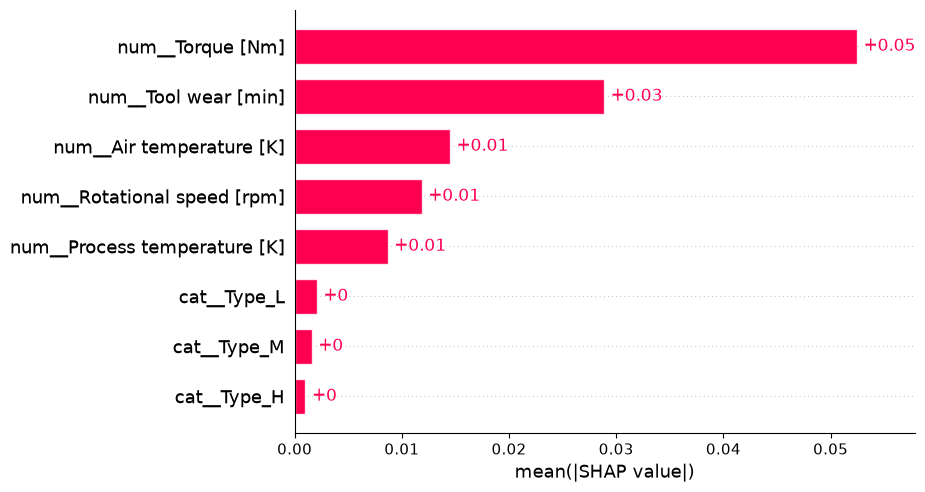

In [46]:
# Step 32: Global Feature Importance

shap.plots.bar(shap_values, max_display=10)

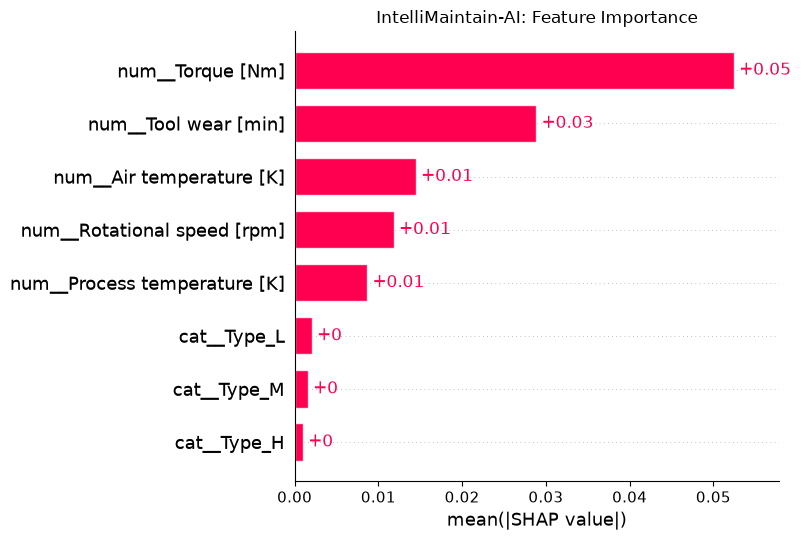

In [47]:
# Step 32: Global Feature Importance

shap_values.feature_names = list(feature_names)

plt.figure(figsize=(10, 6))

shap.plots.bar(
    shap_values,
    max_display=10,
    show=False
)

plt.title("IntelliMaintain-AI: Feature Importance")

plt.tight_layout()
plt.show()

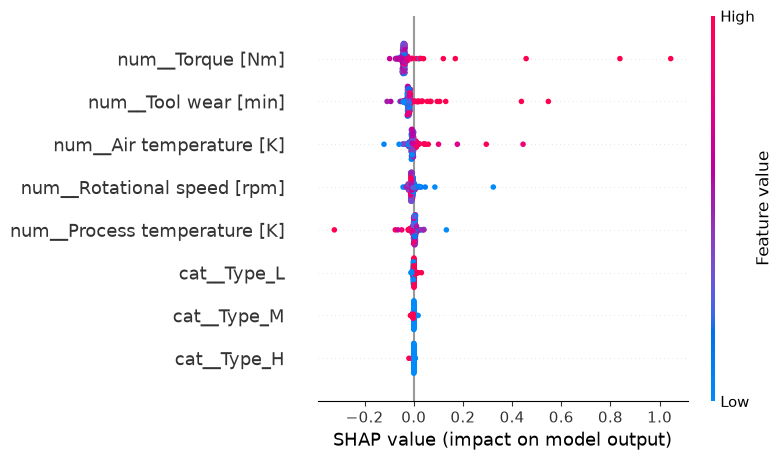

In [43]:
# Step 33: SHAP Summary Plot

shap.summary_plot(
    shap_values.values,
    X_explain,
    feature_names=feature_names,
    show=True
)

Selected SHAP Sample: 0


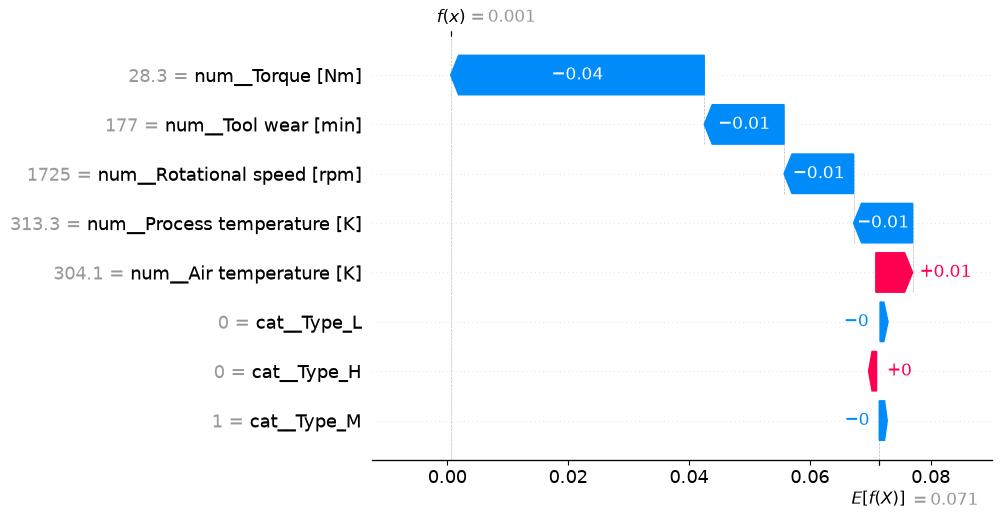

In [49]:
# Step 34: Individual Prediction Explanation

# Select a valid SHAP sample
sample_index = 0

print("Selected SHAP Sample:", sample_index)

# Display SHAP explanation
shap.plots.waterfall(
    shap_values[sample_index],
    max_display=10
)

In [50]:
# Step 35: Save SHAP Explanation

import matplotlib.pyplot as plt
from pathlib import Path

explanation_dir = Path("models/explanations")
explanation_dir.mkdir(parents=True, exist_ok=True)

plt.figure()

shap.plots.waterfall(
    shap_values[sample_index],
    max_display=10,
    show=False
)

plt.savefig(
    explanation_dir / "individual_shap_explanation.png",
    dpi=300,
    bbox_inches="tight"
)

plt.close()

print("SHAP explanation saved successfully!")

SHAP explanation saved successfully!


In [51]:
# Step 36: Save Trained Models

import joblib
from pathlib import Path

models_dir = Path("models")
models_dir.mkdir(exist_ok=True)

# Save Random Forest
joblib.dump(
    rf_model,
    models_dir / "random_forest.pkl"
)

# Save XGBoost
joblib.dump(
    xgb_model,
    models_dir / "xgboost_model.pkl"
)

# Save preprocessing pipeline
joblib.dump(
    preprocessor,
    models_dir / "preprocessor.pkl"
)

print("All models saved successfully!")

All models saved successfully!


In [52]:
# Step 37: Verify Saved Models

from pathlib import Path

models_dir = Path("models")

print("SAVED MODEL FILES:\n")

for file in models_dir.iterdir():
    if file.is_file():
        print(f"✓ {file.name} - {file.stat().st_size / 1024:.2f} KB")

SAVED MODEL FILES:

✓ preprocessor.pkl - 2.42 KB
✓ random_forest.pkl - 7327.10 KB
✓ xgboost_model.pkl - 839.80 KB
